In [1]:
# CELL 1 — Imports & Paths

from pathlib import Path
import pandas as pd
import numpy as np
import torch

from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

seed = 42

import random
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_ROOT = Path().resolve()
DMID_ROOT    = PROJECT_ROOT / "DMID_Dataset"

TIFF_DIR      = DMID_ROOT / "TIFF Images"
METADATA_PATH = DMID_ROOT / "Metadata.xlsx"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("TIFF_DIR:", TIFF_DIR)
print("Metadata exists:", METADATA_PATH.exists())


PROJECT_ROOT: /home/linux-hasan/projects/dmid
TIFF_DIR: /home/linux-hasan/projects/dmid/DMID_Dataset/TIFF Images
Metadata exists: True


In [2]:
# CELL 2 — Load metadata and clean columns

df = pd.read_excel(METADATA_PATH, header=32)

df = df.rename(columns={
    df.columns[0]: "image_id",
    df.columns[1]: "view",
    df.columns[2]: "background",
    df.columns[3]: "abnormality",
    df.columns[4]: "label",
    df.columns[5]: "x",
    df.columns[6]: "y",
    df.columns[7]: "radius",
})

# Keep only Benign (B) / Malignant (M)
df = df[df["label"].isin(["B", "M"])].reset_index(drop=True)
df["label_numeric"] = df["label"].map({"B": 0, "M": 1})

df.head()


,image_id,view,background,abnormality,label,x,y,radius,label_numeric
0,IMG008,CCRT,G,CIRC,B,3211.0,3904.0,216,0
1,IMG010,MLORT,G,CIRC,B,3747.0,4647.0,215,0
2,IMG011,MLORT,G,CIRC,B,3222.0,2557.0,172,0
3,IMG011,MLORT,G,CIRC,B,3242.0,3802.0,258,0
4,IMG012,CCRT,G,CIRC,B,3356.0,3002.0,306,0


In [3]:
# CELL 3 — Map image_id to TIFF image path

image_map = {}
for f in TIFF_DIR.iterdir():
    if f.suffix.lower() in [".tif", ".tiff"]:
        image_map[f.stem] = f

df["image_path"] = df["image_id"].map(image_map)
df = df.dropna(subset=["image_path"]).reset_index(drop=True)

print("Total mammograms (B/M) with TIFF:", len(df))
df[["image_id", "label", "image_path"]].head()


Total mammograms (B/M) with TIFF: 131


,image_id,label,image_path
0,IMG008,B,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
1,IMG010,B,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
2,IMG011,B,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
3,IMG011,B,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
4,IMG012,B,/home/linux-hasan/projects/dmid/DMID_Dataset/T...


In [4]:
# CELL 4 — Filter for rows that have ROI metadata

df_roi = df.dropna(subset=["x", "y", "radius"]).copy()

# Make sure x, y, radius are numeric floats
df_roi["x"]      = pd.to_numeric(df_roi["x"], errors="coerce")
df_roi["y"]      = pd.to_numeric(df_roi["y"], errors="coerce")
df_roi["radius"] = pd.to_numeric(df_roi["radius"], errors="coerce")

df_roi = df_roi.dropna(subset=["x", "y", "radius"]).reset_index(drop=True)

print("Images usable for ROI MIL:", len(df_roi))
df_roi.head()


Images usable for ROI MIL: 128


,image_id,view,background,abnormality,label,x,y,radius,label_numeric,image_path
0,IMG008,CCRT,G,CIRC,B,3211.0,3904.0,216.0,0,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
1,IMG010,MLORT,G,CIRC,B,3747.0,4647.0,215.0,0,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
2,IMG011,MLORT,G,CIRC,B,3222.0,2557.0,172.0,0,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
3,IMG011,MLORT,G,CIRC,B,3242.0,3802.0,258.0,0,/home/linux-hasan/projects/dmid/DMID_Dataset/T...
4,IMG012,CCRT,G,CIRC,B,3356.0,3002.0,306.0,0,/home/linux-hasan/projects/dmid/DMID_Dataset/T...


In [5]:
# CELL 5 — Load original mammogram in grayscale (no resizing)

def load_mammo_original(path):
    img = Image.open(path).convert("L")
    arr = np.array(img).astype(np.float32)
    maxv = arr.max()
    if maxv > 0:
        arr = arr / maxv
    return arr  # shape: (H_orig, W_orig)


In [6]:
# CELL 6 — Get metadata-based bounding box in ORIGINAL resolution

def get_bbox_from_metadata_original(row, orig_img, margin_ratio=0.2):
    H_orig, W_orig = orig_img.shape

    x = float(row["x"])
    y = float(row["y"])
    r = float(row["radius"])

    # base bbox
    x_min = max(0, int(x - r))
    x_max = min(W_orig - 1, int(x + r))
    y_min = max(0, int(y - r))
    y_max = min(H_orig - 1, int(y + r))

    # margin
    h = y_max - y_min
    w = x_max - x_min

    margin_y = int(h * margin_ratio)
    margin_x = int(w * margin_ratio)

    y_min = max(0, y_min - margin_y)
    y_max = min(H_orig - 1, y_max + margin_y)
    x_min = max(0, x_min - margin_x)
    x_max = min(W_orig - 1, x_max + margin_x)

    return y_min, y_max, x_min, x_max


In [7]:
# CELL 7 — Crop ROI, resize, and patchify

ROI_TARGET_SIZE = (512, 512)   # H,W
PATCH_SIZE      = (256, 256)
STRIDE          = (128, 128)

def crop_and_resize_roi(orig_img, bbox, target_size=ROI_TARGET_SIZE):
    y_min, y_max, x_min, x_max = bbox
    roi = orig_img[y_min:y_max+1, x_min:x_max+1]

    roi_pil = Image.fromarray((roi * 255).astype(np.uint8))
    roi_pil = roi_pil.resize(target_size[::-1], Image.BILINEAR)

    roi_arr = np.array(roi_pil).astype(np.float32) / 255.0
    return roi_arr

def extract_patches(arr, patch_size=PATCH_SIZE, stride=STRIDE):
    H, W = arr.shape
    ph, pw = patch_size
    sh, sw = stride

    patches = []
    boxes   = []

    for y in range(0, H - ph + 1, sh):
        for x in range(0, W - pw + 1, sw):
            patch = arr[y:y+ph, x:x+pw]
            patches.append(patch[None, ...])   # (1,ph,pw)
            boxes.append((y, x, ph, pw))

    if not patches:
        return None, None

    patches = np.stack(patches, axis=0)  # (K,1,ph,pw)
    return patches, boxes

def mammo_to_roi_patches(img_path, row):
    orig_img = load_mammo_original(img_path)
    bbox = get_bbox_from_metadata_original(row, orig_img)
    if bbox is None:
        return None, None, None, None

    roi_arr = crop_and_resize_roi(orig_img, bbox)
    patches, boxes = extract_patches(roi_arr)

    if patches is None:
        return None, None, None, None

    patches_t = torch.from_numpy(patches)  # (K,1,256,256)
    return roi_arr, patches_t, boxes, bbox


Image ID: IMG010
Label: 0
ROI patches shape: torch.Size([9, 1, 256, 256])


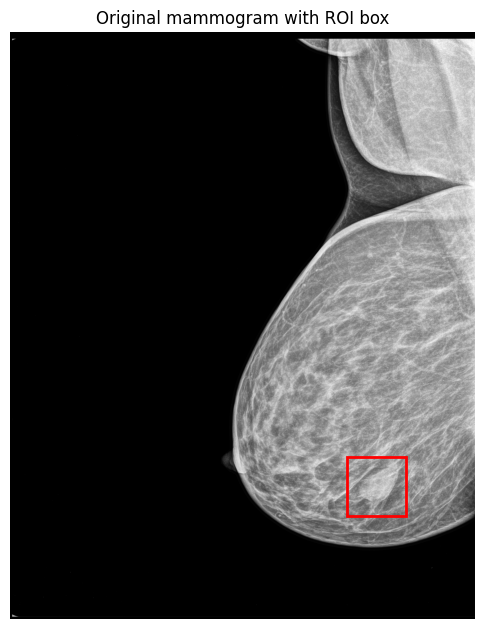

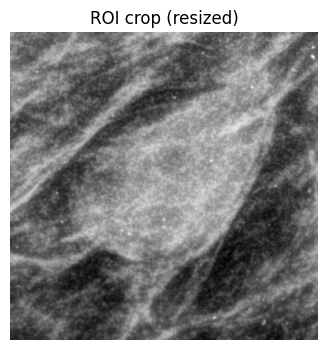

In [8]:
# CELL 8 — Visualize ROI for one example

example = df_roi.iloc[1]

orig_img = load_mammo_original(example["image_path"])
roi_arr, patches_t, boxes, bbox = mammo_to_roi_patches(example["image_path"], example)

print("Image ID:", example["image_id"])
print("Label:", example["label_numeric"])
print("ROI patches shape:", patches_t.shape)

y_min, y_max, x_min, x_max = bbox

plt.figure(figsize=(6,8))
plt.imshow(orig_img, cmap="gray")
rect = Rectangle((x_min, y_min), x_max-x_min, y_max-y_min,
                 edgecolor="red", fill=False, linewidth=2)
plt.gca().add_patch(rect)
plt.title("Original mammogram with ROI box")
plt.axis("off")
plt.show()

plt.figure(figsize=(4,4))
plt.imshow(roi_arr, cmap="gray")
plt.title("ROI crop (resized)")
plt.axis("off")
plt.show()


In [9]:
# CELL 9 — Build ROI MIL bags and save as .pt

ROI_BAGS_DIR = PROJECT_ROOT / "roi_mil_bags_final"
ROI_BAGS_DIR.mkdir(exist_ok=True)

roi_bag_records = []

for idx, row in df_roi.iterrows():
    roi_arr, patches_t, boxes, bbox = mammo_to_roi_patches(row["image_path"], row)

    if patches_t is None:
        continue

    save_path = ROI_BAGS_DIR / f"{row['image_id']}.pt"

    torch.save({
        "image_id": row["image_id"],
        "label": int(row["label_numeric"]),
        "patches": patches_t
    }, save_path)

    roi_bag_records.append({
        "image_id": row["image_id"],
        "label": int(row["label_numeric"]),
        "num_patches": patches_t.shape[0],
        "bag_path": save_path
    })

len(roi_bag_records)


128

In [10]:
# CELL 10 — ROI bag stats

roi_bags_df = pd.DataFrame(roi_bag_records)
print("Total ROI bags:", len(roi_bags_df))
roi_bags_df.head()


Total ROI bags: 128


,image_id,label,num_patches,bag_path
0,IMG008,0,9,/home/linux-hasan/projects/dmid/roi_mil_bags_f...
1,IMG010,0,9,/home/linux-hasan/projects/dmid/roi_mil_bags_f...
2,IMG011,0,9,/home/linux-hasan/projects/dmid/roi_mil_bags_f...
3,IMG011,0,9,/home/linux-hasan/projects/dmid/roi_mil_bags_f...
4,IMG012,0,9,/home/linux-hasan/projects/dmid/roi_mil_bags_f...


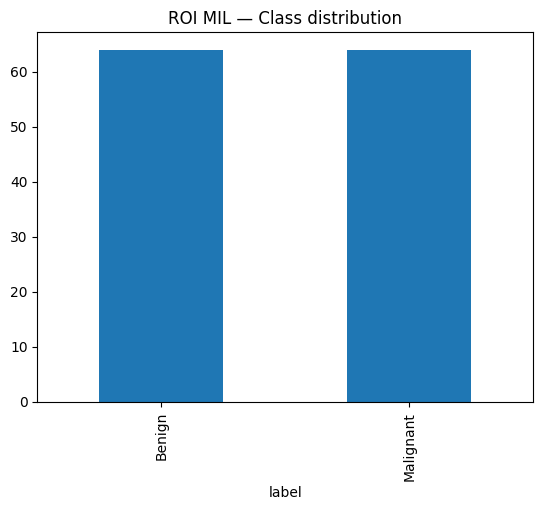

In [11]:
# Class distribution
roi_bags_df["label"].map({0:"Benign", 1:"Malignant"}).value_counts().plot(kind="bar")
plt.title("ROI MIL — Class distribution")
plt.show()


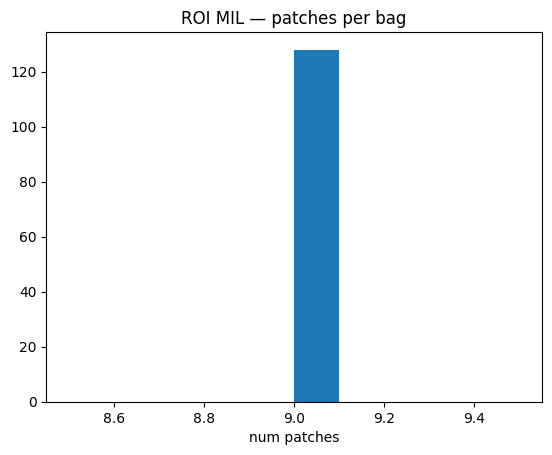

In [12]:
# Patch count distribution
plt.hist(roi_bags_df["num_patches"], bins=10)
plt.title("ROI MIL — patches per bag")
plt.xlabel("num patches")
plt.show()


In [13]:
# Check one bag file
test_bag = torch.load(roi_bags_df.iloc[0]["bag_path"])
print("ID:", test_bag["image_id"])
print("Label:", test_bag["label"])
print("Patches shape:", test_bag["patches"].shape)


ID: IMG008
Label: 0
Patches shape: torch.Size([9, 1, 256, 256])


In [14]:
# CELL 11 — Train/Val/Test split

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    roi_bags_df,
    test_size=0.30,
    stratify=roi_bags_df["label"],
    random_state=42
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# VERY IMPORTANT: reset index here
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Train: 89 Val: 19 Test: 20


In [15]:
# CELL 12 — MILDataset and DataLoaders

from torch.utils.data import Dataset, DataLoader

class MILDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        bag = torch.load(row["bag_path"])
        patches = bag["patches"].float()          # (K,1,256,256)
        label   = torch.tensor(bag["label"]).long()
        return patches, label

def mil_collate_fn(batch):
    patches_list = [item[0] for item in batch]
    labels = torch.stack([item[1] for item in batch])
    return patches_list, labels

train_dataset = MILDataset(train_df)
val_dataset   = MILDataset(val_df)
test_dataset  = MILDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True,  collate_fn=mil_collate_fn)
val_loader   = DataLoader(val_dataset,   batch_size=1, shuffle=False, collate_fn=mil_collate_fn)
test_loader  = DataLoader(test_dataset,  batch_size=1, shuffle=False, collate_fn=mil_collate_fn)

len(train_dataset), len(val_dataset), len(test_dataset)


(89, 19, 20)

In [16]:
# CELL 13 — Attention MIL model definition

import torch.nn as nn
from torchvision.models import resnet18

def get_resnet18_feature_extractor(pretrained=True):
    model = resnet18(weights="IMAGENET1K_V1" if pretrained else None)

    old_conv1 = model.conv1
    new_conv1 = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv1.out_channels,
        kernel_size=old_conv1.kernel_size,
        stride=old_conv1.stride,
        padding=old_conv1.padding,
        bias=old_conv1.bias is not None,
    )
    with torch.no_grad():
        new_conv1.weight[:] = old_conv1.weight.mean(dim=1, keepdim=True)
    model.conv1 = new_conv1

    modules = list(model.children())[:-1]  # remove final FC
    feature_extractor = nn.Sequential(*modules)
    feature_dim = 512
    return feature_extractor, feature_dim


class GatedAttention(nn.Module):
    def __init__(self, in_dim, hidden_dim=128):
        super().__init__()
        self.V = nn.Linear(in_dim, hidden_dim)
        self.U = nn.Linear(in_dim, hidden_dim)
        self.w = nn.Linear(hidden_dim, 1)

    def forward(self, H):
        Vh = torch.tanh(self.V(H))
        Uh = torch.sigmoid(self.U(H))
        Vu = Vh * Uh
        logits = self.w(Vu).squeeze(1)
        A = torch.softmax(logits, dim=0)
        return A


class AttentionMIL(nn.Module):
    def __init__(self, pretrained_backbone=True, att_hidden_dim=128):
        super().__init__()
        self.encoder, feat_dim = get_resnet18_feature_extractor(pretrained_backbone)
        self.attention = GatedAttention(feat_dim, att_hidden_dim)
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, patches):
        K = patches.size(0)
        feats = self.encoder(patches)        # (K,512,1,1)
        feats = feats.view(K, -1)            # (K,512)
        A = self.attention(feats)            # (K,)
        M = torch.sum(A.unsqueeze(1) * feats, dim=0)  # (512,)
        logit = self.classifier(M).squeeze(0)
        prob  = torch.sigmoid(logit)
        return logit, prob, A


In [17]:
# CELL 14 — Train & validation loops

import torch.nn.functional as F
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AttentionMIL(pretrained_backbone=True).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for patches_list, labels in loader:
        patches = patches_list[0].to(device)
        labels  = labels.float().to(device)

        optimizer.zero_grad()
        logit, prob, _ = model(patches)
        loss = criterion(logit.unsqueeze(0), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        pred = (prob >= 0.5).long()
        correct += (pred == labels.long()).sum().item()
        total += 1

    return total_loss/total, correct/total


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for patches_list, labels in loader:
            patches = patches_list[0].to(device)
            labels  = labels.float().to(device)

            logit, prob, _ = model(patches)
            loss = criterion(logit.unsqueeze(0), labels)

            total_loss += loss.item()
            pred = (prob >= 0.5).long()
            correct += (pred == labels.long()).sum().item()
            total += 1
    return total_loss/total, correct/total


Using device: cuda


In [18]:
# CELL 15 — Train ROI MIL

EPOCHS = 50
best_val_acc = 0.0
best_model_path = PROJECT_ROOT / "best_roi_mil_model.pt"

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []

for epoch in range(1, EPOCHS+1):
    print(f"\n🔥 Epoch {epoch}/{EPOCHS}")

    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    va_loss, va_acc = evaluate(model, val_loader)

    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accs.append(tr_acc)
    val_accs.append(va_acc)

    print(f"Train Loss: {tr_loss:.4f} | Acc: {tr_acc:.4f}")
    print(f"Val   Loss: {va_loss:.4f} | Acc: {va_acc:.4f}")

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), best_model_path)
        print("💾 Saved new best ROI MIL model!")

print("\nTraining complete. Best Val Acc:", best_val_acc)



🔥 Epoch 1/50
Train Loss: 0.7443 | Acc: 0.5281
Val   Loss: 1.0509 | Acc: 0.6316
💾 Saved new best ROI MIL model!

🔥 Epoch 2/50
Train Loss: 0.4096 | Acc: 0.8202
Val   Loss: 1.3202 | Acc: 0.4211

🔥 Epoch 3/50
Train Loss: 0.2296 | Acc: 0.9213
Val   Loss: 1.2612 | Acc: 0.4737

🔥 Epoch 4/50
Train Loss: 0.0398 | Acc: 1.0000
Val   Loss: 1.0617 | Acc: 0.6316

🔥 Epoch 5/50
Train Loss: 0.0082 | Acc: 1.0000
Val   Loss: 0.9936 | Acc: 0.6842
💾 Saved new best ROI MIL model!

🔥 Epoch 6/50
Train Loss: 0.0019 | Acc: 1.0000
Val   Loss: 0.4702 | Acc: 0.7895
💾 Saved new best ROI MIL model!

🔥 Epoch 7/50
Train Loss: 0.0011 | Acc: 1.0000
Val   Loss: 0.5634 | Acc: 0.7895

🔥 Epoch 8/50
Train Loss: 0.0008 | Acc: 1.0000
Val   Loss: 0.5206 | Acc: 0.8421
💾 Saved new best ROI MIL model!

🔥 Epoch 9/50
Train Loss: 0.0006 | Acc: 1.0000
Val   Loss: 0.5351 | Acc: 0.8421

🔥 Epoch 10/50
Train Loss: 0.0005 | Acc: 1.0000
Val   Loss: 0.5688 | Acc: 0.6842

🔥 Epoch 11/50
Train Loss: 0.0004 | Acc: 1.0000
Val   Loss: 0.8090 | Ac

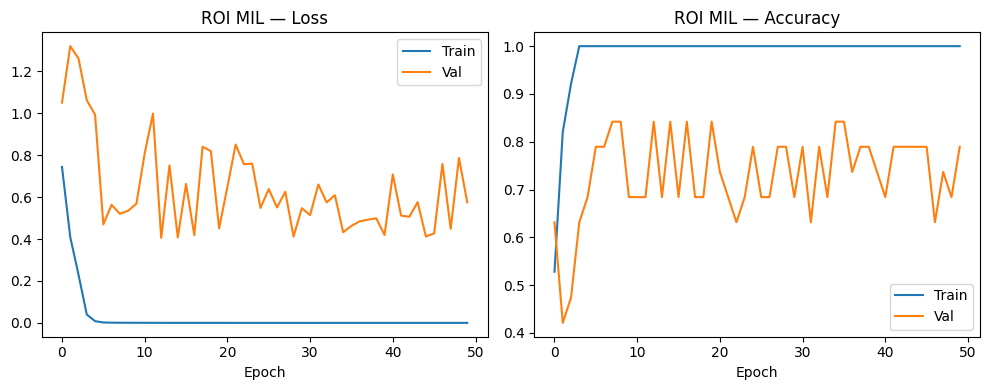

In [19]:
# CELL 16 — Plot training curves

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Val")
plt.title("ROI MIL — Loss")
plt.xlabel("Epoch"); plt.legend()

plt.subplot(1,2,2)
plt.plot(train_accs, label="Train")
plt.plot(val_accs, label="Val")
plt.title("ROI MIL — Accuracy")
plt.xlabel("Epoch"); plt.legend()

plt.tight_layout()
plt.show()


=== ROI MIL TEST METRICS ===
Accuracy:    0.8500
F1 Score:    0.8000
AUC:         0.8889
Sensitivity: 0.6667
Specificity: 1.0000


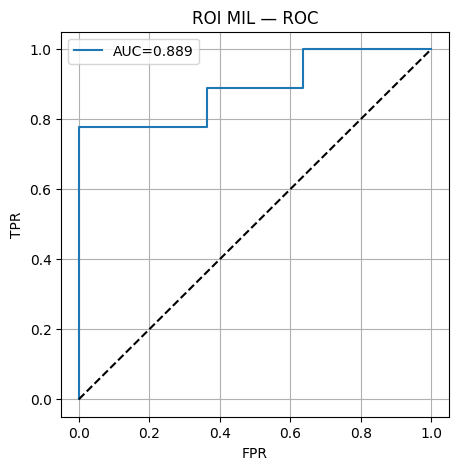

In [20]:
# CELL 17 — Test metrics & ROC

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

best_model = AttentionMIL(pretrained_backbone=False).to(device)
best_model.load_state_dict(torch.load(best_model_path))
best_model.eval()

def infer(loader):
    y_true, y_prob = [], []
    with torch.no_grad():
        for patches_list, labels in loader:
            patches = patches_list[0].to(device)
            labels  = labels.to(device)
            logit, prob, _ = best_model(patches)
            y_true.append(labels.item())
            y_prob.append(prob.item())
    return np.array(y_true), np.array(y_prob)

y_true, y_prob = infer(test_loader)
y_pred = (y_prob >= 0.5).astype(int)

acc  = accuracy_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred)
auc  = roc_auc_score(y_true, y_prob)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
sens = tp / (tp + fn)
spec = tn / (tn + fp)

print("=== ROI MIL TEST METRICS ===")
print(f"Accuracy:    {acc:.4f}")
print(f"F1 Score:    {f1:.4f}")
print(f"AUC:         {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")

fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROI MIL — ROC")
plt.legend(); plt.grid(True)
plt.show()


In [21]:
total_roi_patches = sum([d["num_patches"] for d in roi_bag_records])
total_roi_patches

1152